# PRAKTIKUM 02 — Input Space dan Feature Space

**Seri:** *From Data to Machine Learning*  
**Level:** Pemula–menengah awal | **Durasi anjuran:** 100–120 menit (+ latihan) | **Moda:** demonstrasi dan praktik terbimbing  
**Fokus:** bagaimana **data tabular, teks, dan citra** menjadi representasi fitur numerik.

**Dataset asli:** `Data.csv` (tabular), `Dataset_Sentimen_Emosi.csv` (teks), dan `fruits.png` (citra), seluruhnya dari paket workshop.

> **Posisi modul:** Praktikum 01 mempelajari Python dan eksplorasi data. Praktikum **02** mempelajari *apa itu representasi fitur* dan bagaimana membaca koordinat/dimensinya. Praktikum **03** baru membahas pembersihan data, imputasi, normalisasi/scaling, pembagian train–test, dan pencegahan *data leakage*. Praktikum 04 memulai pemodelan klasifikasi.

**Petunjuk:** Jalankan dari atas dengan **Kernel → Restart & Run All**. Pelajari output satu per satu; latihan dan kunci jawaban berada di bagian akhir.

## A. Capaian pembelajaran dan alur

Setelah praktikum, mahasiswa mampu:

1. Menjelaskan perbedaan **input space** (ruang data asal) dan **feature space** (ruang koordinat representasi fitur), serta membedakan **sampel, fitur, target,** dan **dimensi**.
2. Merepresentasikan satu sampel sebagai vektor dan banyak sampel sebagai matriks `X` berukuran `(n_samples, n_features)`.
3. Mengubah kategori nominal ke indikator numerik menggunakan **One-Hot Encoding**, kemudian memeriksa nama dan jumlah fiturnya.
4. Menjelaskan **Count Vector** dan **TF-IDF**, menampilkan fitur nonnol dari satu dokumen, dan memvisualisasikan distribusi term antardokumen.
5. Membaca citra RGB sebagai array `(height, width, channels)`, mengambil nilai piksel, mengecilkan citra untuk demonstrasi, dan melakukan *flatten*.
6. Membandingkan **arti koordinat dan konsekuensi perubahan dimensi** pada data tabular, teks, dan citra.

**Alur:** `Konsep dasar → Tabular + One-Hot → Teks + TF-IDF → Citra RGB → Perbandingan → Latihan → Kunci jawaban`.

**Batasan:** Praktikum ini **tidak** melatih model prediksi dan **tidak** melakukan normalisasi atau imputasi. Kedua kegiatan itu memiliki fokus tersendiri pada Praktikum 03.

## B. Persiapan environment dan dataset

Paket yang diperlukan: Python 3.10+, `numpy`, `pandas`, `matplotlib`, `Pillow`, `scikit-learn`, dan Jupyter/IPython.

Instalasi di terminal (jika belum tersedia):

```bash
python -m pip install numpy pandas matplotlib pillow scikit-learn jupyterlab
```

Struktur **paket mandiri** yang didukung:

```text
Praktikum_02/
├── 02_Input_Space_dan_Feature_Space_Modul_Final_dan_Jawaban.ipynb
└── data/
    ├── Data.csv
    ├── Dataset_Sentimen_Emosi.csv
    └── fruits.png
```

Notebook juga mendukung struktur dataset **paket workshop asli** (`praktikum/data/`). Tidak menggunakan data simulasi sebagai pengganti otomatis: jika data tidak ditemukan, perbaiki lokasinya.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

REQUIRED = ('../data/Data.csv', '../data/Dataset_Sentimen_Emosi.csv', '../data/fruits.png')
BASES = [Path.cwd(), *Path.cwd().parents]
REL_DIRS = (Path('data'), Path('praktikum/data'),
            Path('Workshop_From_Data_to_ML/praktikum/data'))
DATA_DIR = next(
    (base / sub for base in BASES for sub in REL_DIRS
     if all((base / sub / name).is_file() for name in REQUIRED)),
    None
)
if DATA_DIR is None:
    raise FileNotFoundError(
        'Tiga berkas asli tidak ditemukan. Simpan Data.csv, '
        'Dataset_Sentimen_Emosi.csv, fruits.png di folder data/ '
        'di samping notebook atau gunakan struktur paket workshop.'
    )

print('Python       :', sys.version.split()[0])
print('Folder data :', DATA_DIR.resolve())
print('Dataset     :', list(REQUIRED))

Python       : 3.10.18
Folder data : /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/final_release/Workshop_From_Data_to_ML/praktikum/data
Dataset     : ['../data/Data.csv', '../data/Dataset_Sentimen_Emosi.csv', '../data/fruits.png']


### B1. Memeriksa berkas dan memahami ukuran sumber

Sebelum transformasi, pastikan tiga file tersedia. Ukuran berkas fisik berbeda dari **shape** setelah dibaca sebagai matriks atau tensor.

In [2]:
for name in REQUIRED:
    path = DATA_DIR / name
    print(f'{name:32s} | {path.stat().st_size:>9,} byte')

../data/Data.csv                 |       216 byte
../data/Dataset_Sentimen_Emosi.csv |   127,256 byte
../data/fruits.png               |   343,208 byte


## C. Konsep dasar: observasi, fitur, dan dimensi

Misalkan tiga mahasiswa dicatat berdasarkan usia dan jumlah mata kuliah yang diambil. Setiap mahasiswa adalah **satu sampel (observasi)**; usia dan jumlah mata kuliah adalah **dua fitur**.

Satu sampel dapat ditulis sebagai vektor $\mathbf{x}^{(i)}=[x_1^{(i)},x_2^{(i)}]$. Beberapa sampel membentuk matriks fitur:

$$
X=\begin{bmatrix}
20&6\\
21&7\\
19&5
\end{bmatrix}\in\mathbb{R}^{3\times2}.
$$

`X.shape == (3, 2)` berarti **3 sampel × 2 fitur**. Jika tersedia label kelulusan `y`, label itu bukan koordinat fitur input dan disimpan terpisah.

**Input space** adalah domain atau bentuk asal informasi (misalnya `Country` sebagai nama negara, kalimat tweet, atau piksel citra). **Feature space** adalah representasi koordinat yang dibuat/ditetapkan untuk diproses algoritma. Nilai asal yang sudah numerik pun bisa langsung menjadi fitur; tidak semua fitur harus di-*encode*.

In [3]:
X_demo = np.array([[20, 6], [21, 7], [19, 5]])
y_demo = np.array(['Lulus', 'Lulus', 'Belum'])

print('Satu sampel    :', X_demo[0])
print('Shape sampel   :', X_demo[0].shape)
print('Matriks X:\n', X_demo)
print('Shape matriks  :', X_demo.shape)
print('Target y       :', y_demo)
print('Panjang target :', len(y_demo))

Satu sampel    : [20  6]
Shape sampel   : (2,)
Matriks X:
 [[20  6]
 [21  7]
 [19  5]]
Shape matriks  : (3, 2)
Target y       : ['Lulus' 'Lulus' 'Belum']
Panjang target : 3


### C1. Eksperimen sederhana: apa yang terjadi jika satu fitur ditambah?

Contoh berikut menambahkan fitur ketiga berupa jam belajar mingguan. Banyak sampel tetap tiga, tetapi dimensi fitur menjadi tiga.

In [4]:
jam_belajar = np.array([8, 10, 6])
X_demo_3 = np.column_stack([X_demo, jam_belajar])

display(pd.DataFrame(X_demo_3,
                     columns=['Usia', 'Mata_Kuliah', 'Jam_Belajar']))
print('Sebelum:', X_demo.shape, '| Sesudah:', X_demo_3.shape)

,Usia,Mata_Kuliah,Jam_Belajar
0,20,6,8
1,21,7,10
2,19,5,6


Sebelum: (3, 2) | Sesudah: (3, 3)


## D. Data tabular: kategori → koordinat One-Hot

### D1. Input Space dari `Data.csv`

Dataset berisi `Country`, `Age`, `Salary`, dan `Purchased`. Dalam demonstrasi ini:

- `Country` bertipe **kategori nominal**: `France`, `Germany`, `Spain`; kategori tidak memiliki urutan numerik yang logis.
- `Age` dan `Salary` bertipe numerik dan **dipertahankan nilainya** pada modul ini.
- `Purchased` adalah **target**, bukan fitur input.

Tabel mengandung nilai kosong pada `Age` dan `Salary`. Nilai tersebut **tidak diperbaiki di sini** karena penanganan missing value merupakan Praktikum 03. Artinya, `X_tabular` yang kita bentuk adalah **hasil representasi**, belum otomatis siap untuk semua model ML.

In [5]:
data = pd.read_csv(DATA_DIR / 'Data.csv')
print('=== INPUT SPACE: DATA ASLI ===')
display(data)
print('Shape seluruh data:', data.shape)
print('\nTipe data:')
print(data.dtypes)

=== INPUT SPACE: DATA ASLI ===


,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,NaN,Yes
5,France,35.0,58000.0,Yes
6,Spain,NaN,52000.0,No
7,France,48.0,79000.0,Yes
8,Germany,50.0,83000.0,No
9,France,37.0,67000.0,Yes


Shape seluruh data: (10, 4)

Tipe data:
Country       object
Age          float64
Salary       float64
Purchased     object
dtype: object


### D2. Pisahkan fitur (`X`) dan target (`y`)

Pemisahan konseptual penting: saat memprediksi `Purchased`, nilainya tidak boleh digunakan sebagai input karena akan membocorkan jawaban.

In [6]:
target_col = 'Purchased'
X_raw = data.drop(columns=target_col)
y = data[target_col].copy()

categorical_cols = X_raw.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()
numerical_cols = X_raw.select_dtypes(include='number').columns.tolist()

print('Input X:', X_raw.shape, '| Target y:', y.shape)
print('Kolom numerik    :', numerical_cols)
print('Kolom kategorikal:', categorical_cols)
print('Nilai kosong per fitur:')
display(X_raw.isna().sum().rename('Jumlah nilai kosong').to_frame())

Input X: (10, 3) | Target y: (10,)
Kolom numerik    : ['Age', 'Salary']
Kolom kategorikal: ['Country']
Nilai kosong per fitur:


,Jumlah nilai kosong
Country,0
Age,1
Salary,1


### D3. Mengapa One-Hot, bukan memberi nomor 0, 1, 2?

Pemberian nomor `France=0`, `Germany=1`, `Spain=2` dapat terbaca seolah-olah ada **jarak dan urutan**, padahal itu kategori nominal. *One-Hot Encoding* membuat indikator untuk tiap kategori:

| Country | Country_France | Country_Germany | Country_Spain |
|---|---:|---:|---:|
| France | 1 | 0 | 0 |
| Germany | 0 | 1 | 0 |
| Spain | 0 | 0 | 1 |

Satu kategori aktif (`1`) pada tiap baris, sedangkan kategori lain `0`.

In [7]:
enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
country_encoded = enc.fit_transform(X_raw[categorical_cols])

encoded_names = enc.get_feature_names_out(categorical_cols)
df_country = pd.DataFrame(
    country_encoded, columns=encoded_names, index=X_raw.index
).astype(int)

print('Kategori yang dipelajari:', [list(c) for c in enc.categories_])
print('Shape One-Hot:', df_country.shape)
display(pd.concat([X_raw[categorical_cols], df_country], axis=1))

Kategori yang dipelajari: [['France', 'Germany', 'Spain']]
Shape One-Hot: (10, 3)


,Country,Country_France,Country_Germany,Country_Spain
0,France,1,0,0
1,Spain,0,0,1
2,Germany,0,1,0
3,Spain,0,0,1
4,Germany,0,1,0
5,France,1,0,0
6,Spain,0,0,1
7,France,1,0,0
8,Germany,0,1,0
9,France,1,0,0


### D4. Bentuk **Final Feature Space** (sebelum preprocessing)

Gabungkan fitur numerik asli dengan kolom One-Hot. Output memiliki **satu baris per sampel** dan **satu kolom per fitur representasi**.

Perhatian: istilah *final* di sini berarti **akhir tahap feature representation**, bukan hasil akhir tahap preprocessing. Nilai `NaN` tetap ada sampai Praktikum 03.

In [8]:
X_tabular = pd.concat([X_raw[numerical_cols], df_country], axis=1)

print('=== FINAL TABULAR FEATURE SPACE (BELUM IMPUTASI/SCALING) ===')
display(X_tabular)
print('Shape Input Space X_raw :', X_raw.shape)
print('Shape Feature Space     :', X_tabular.shape)
print('Nama fitur              :', X_tabular.columns.tolist())

=== FINAL TABULAR FEATURE SPACE (BELUM IMPUTASI/SCALING) ===


,Age,Salary,Country_France,Country_Germany,Country_Spain
0,44.0,72000.0,1,0,0
1,27.0,48000.0,0,0,1
2,30.0,54000.0,0,1,0
3,38.0,61000.0,0,0,1
4,40.0,NaN,0,1,0
5,35.0,58000.0,1,0,0
6,NaN,52000.0,0,0,1
7,48.0,79000.0,1,0,0
8,50.0,83000.0,0,1,0
9,37.0,67000.0,1,0,0


Shape Input Space X_raw : (10, 3)
Shape Feature Space     : (10, 5)
Nama fitur              : ['Age', 'Salary', 'Country_France', 'Country_Germany', 'Country_Spain']


### D5. Fokus **satu sampel**: vektor fitur dan targetnya

Kita pilih **record pertama** (indeks Python `0`). Visualisasikan: data asal, vektor fitur numerik, dan target secara **terpisah**.

In [9]:
idx_tabular = 0
print('Sampel asli (record ke-1):')
display(data.iloc[[idx_tabular]])

print('Vektor fitur X[0]:')
display(X_tabular.iloc[[idx_tabular]])
print('Sebagai array:', X_tabular.iloc[idx_tabular].to_numpy())
print('Target y[0]:', y.iloc[idx_tabular])

Sampel asli (record ke-1):


,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No


Vektor fitur X[0]:


,Age,Salary,Country_France,Country_Germany,Country_Spain
0,44.0,72000.0,1,0,0


Sebagai array: [4.4e+01 7.2e+04 1.0e+00 0.0e+00 0.0e+00]
Target y[0]: No


### D6. Visualisasi One-Hot untuk seluruh sampel

**Heatmap** berikut hanya memvisualisasikan kolom kategori agar pola indikator `0` dan `1` terlihat jelas. Kolom `Age` dan `Salary` tidak dimasukkan karena skala numeriknya berbeda.

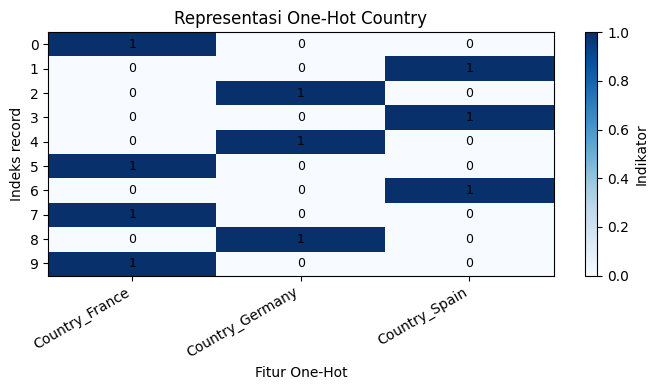

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
heat = ax.imshow(df_country.to_numpy(), aspect='auto', interpolation='nearest',
                 vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(len(df_country.columns)), df_country.columns, rotation=30, ha='right')
ax.set_yticks(range(len(df_country)), [f'{i}' for i in df_country.index])
ax.set_xlabel('Fitur One-Hot')
ax.set_ylabel('Indeks record')
ax.set_title('Representasi One-Hot Country')
for r in range(len(df_country)):
    for c in range(df_country.shape[1]):
        ax.text(c, r, str(df_country.iat[r, c]), ha='center', va='center', fontsize=9)
fig.colorbar(heat, ax=ax, label='Indikator')
plt.tight_layout()
plt.show()

### D7. Bagaimana jika ada kategori baru?

`handle_unknown='ignore'` membuat kategori yang tidak ada saat `fit`, seperti `Italy`, menjadi semua nol pada kolom `Country_*`. Ini berguna untuk menjaga jumlah kolom saat `transform`, tetapi bisa menimbulkan **ambiguity** (semua nol tidak menyatakan satu kategori lama secara eksplisit).

Di praktikum ini `fit` memakai seluruh data semata-mata untuk ilustrasi transformasi. Pada pelatihan model sungguhan, encoder harus di-**fit hanya pada data training**, sebagaimana dibahas di Praktikum 03.

In [11]:
country_baru = pd.DataFrame({'Country': ['Italy', 'France']})
hasil_baru = pd.DataFrame(
    enc.transform(country_baru), columns=encoded_names
).astype(int)
display(pd.concat([country_baru, hasil_baru], axis=1))

,Country,Country_France,Country_Germany,Country_Spain
0,Italy,0,0,0
1,France,1,0,0


### D8. Interpretasi tahap tabular

- `X_raw` berisi **3 kolom input** (`Country`, `Age`, `Salary`).
- `X_tabular` berisi **5 kolom representasi fitur** (`Age`, `Salary`, dan tiga indikator negara).
- Jumlah **baris tidak berubah** (10 sampel).
- `Purchased` tetap di `y`, bukan di `X_tabular`.
- Missing value pada `Age`/`Salary` belum diimputasi; itu **bukan kegagalan One-Hot Encoding**, melainkan isu kualitas data di tahap berikutnya.

**Pertanyaan cek pemahaman:** Mengapa menambah fitur dapat mengubah jumlah kolom, tetapi tidak selalu mengubah jumlah sampel?

## E. Representasi teks: kalimat → vektor term

Berbeda dari tabel, kalimat memiliki panjang dan urutan kata yang bervariasi. Untuk model yang menerima matriks numerik, teks perlu dikonversi menjadi koordinat, misalnya:

- **Bag of Words / CountVectorizer:** setiap koordinat mewakili satu term; nilainya adalah jumlah kemunculan term.
- **TF-IDF:** setiap koordinat mewakili satu term; nilainya membobot term berdasarkan frekuensi di dokumen dan persebarannya antardokumen.

**Keterbatasan:** Count Vector dan TF-IDF berbasis kosakata, sehingga representasi dasar ini **tidak secara langsung mempertahankan urutan kata atau makna kontekstual mendalam**.

### E1. Percobaan kecil agar mudah dibaca

Mulai dengan tiga kalimat **buatan untuk demonstrasi** agar matriks term mudah diamati. Setelah itu, gunakan dataset teks asli berisi 905 record.

In [12]:
contoh_korpus = [
    'data penting untuk belajar',
    'belajar data dengan python',
    'python untuk analisis data'
]
vector_count = CountVectorizer()
X_count = vector_count.fit_transform(contoh_korpus)

print('Daftar term:', vector_count.get_feature_names_out().tolist())
print('Shape Bag of Words:', X_count.shape)
display(pd.DataFrame(
    X_count.toarray(), columns=vector_count.get_feature_names_out(),
    index=['Dokumen 0', 'Dokumen 1', 'Dokumen 2']
))

Daftar term: ['analisis', 'belajar', 'data', 'dengan', 'penting', 'python', 'untuk']
Shape Bag of Words: (3, 7)


,analisis,belajar,data,dengan,penting,python,untuk
Dokumen 0,0,1,1,0,1,0,1
Dokumen 1,0,1,1,1,0,1,0
Dokumen 2,1,0,1,0,0,1,1


### E2. TF-IDF dari korpus kecil

Pada versi scikit-learn, bobot TF-IDF standar memakai **IDF yang dihaluskan** (*smooth IDF*) dan normalisasi L2 pada setiap dokumen secara default. Secara konseptual:

$$\mathrm{TF\!\mbox{-}\!IDF}(t,d)=\mathrm{TF}(t,d)\times\mathrm{IDF}(t)$$

Term yang muncul pada hampir semua dokumen biasanya memperoleh IDF lebih rendah daripada term yang lebih jarang. Namun, nilai akhir juga dipengaruhi frekuensi term, pilihan parameter, dan normalisasi; **nilai TF-IDF bukan probabilitas**.

In [13]:
vector_toy = TfidfVectorizer()
X_toy = vector_toy.fit_transform(contoh_korpus)

display(pd.DataFrame(
    X_toy.toarray(), columns=vector_toy.get_feature_names_out(),
    index=['Dokumen 0', 'Dokumen 1', 'Dokumen 2']
).round(3))
print('IDF tiap term:')
display(pd.DataFrame({
    'Term': vector_toy.get_feature_names_out(),
    'IDF': vector_toy.idf_
}).round(3))

,analisis,belajar,data,dengan,penting,python,untuk
Dokumen 0,0.000,0.48,0.373,0.000,0.632,0.00,0.48
Dokumen 1,0.000,0.48,0.373,0.632,0.000,0.48,0.00
Dokumen 2,0.632,0.00,0.373,0.000,0.000,0.48,0.48


IDF tiap term:


,Term,IDF
0,analisis,1.693
1,belajar,1.288
2,data,1.000
3,dengan,1.693
4,penting,1.693
5,python,1.288
6,untuk,1.288


### E3. Baca dataset teks asli

Dataset sumber memiliki kolom `Tweet`, `Sentimen`, dan `Emosi`. **Hanya kolom `Tweet`** yang digunakan sebagai input representasi teks; dua kolom lainnya adalah label/metadata dan **tidak dilibatkan** dalam proses `fit_transform()` ini.

Contoh tweet bisa mengandung bahasa percakapan/ungkapan keras, karena merupakan data teks asli.

In [14]:
df_text = pd.read_csv(DATA_DIR / 'Dataset_Sentimen_Emosi.csv')
print('Shape dataset teks:', df_text.shape)
print('Nama kolom:', df_text.columns.tolist())
print('Jumlah Tweet kosong:', df_text['Tweet'].isna().sum())
print('Label Sentimen kosong:', df_text['Sentimen'].isna().sum())
display(df_text.head(3))

Shape dataset teks: (905, 3)
Nama kolom: ['Tweet', 'Sentimen', 'Emosi']
Jumlah Tweet kosong: 0
Label Sentimen kosong: 1


,Tweet,Sentimen,Emosi
0,"emang lemes bgt ya mulut lu, gue yg mau beli-b...",-1.0,-2
1,"Cegah mata rantai Covid-19,mari kita dirumah s...",1.0,1
2,aku mohon yaAllah semoga wabah covid-19 menghi...,1.0,-1


### E4. Vektorisasi TF-IDF — membentuk matriks fitur

`max_features=300` membatasi **jumlah term maksimal** yang dipilih dari korpus. `TfidfVectorizer` menghasilkan *sparse matrix*: elemen bernilai nol tidak perlu semuanya disimpan.

Pada kasus ini baris = dokumen, kolom = term kosakata. Untuk pembelajaran representasi, `fit_transform` digunakan pada seluruh dokumen yang tersedia. Pada **pemodelan klasifikasi**, kosakata dan IDF wajib di-*fit pada data train saja*.

In [15]:
documents = df_text['Tweet'].fillna('').astype(str).reset_index(drop=True)
tfidf = TfidfVectorizer(max_features=300)
Xt = tfidf.fit_transform(documents)
terms = tfidf.get_feature_names_out()

print('Dokumen                :', len(documents))
print('Matriks fitur (sparse) :', Xt.shape)
print('Jumlah fitur kosakata  :', len(terms))
print('Nilai nonnol seluruh X:', Xt.nnz)
print('Rasio sel nonnol       :', f'{Xt.nnz / (Xt.shape[0] * Xt.shape[1]):.2%}')
print('Tipe objek             :', type(Xt).__name__)

Dokumen                : 905
Matriks fitur (sparse) : (905, 300)
Jumlah fitur kosakata  : 300
Nilai nonnol seluruh X: 8653
Rasio sel nonnol       : 3.19%
Tipe objek             : csr_matrix


### E5. **Satu record dokumen**: teks asal dan fitur TF-IDF

Baris `Xt[idx]` merupakan vektor dari satu dokumen. Lakukan `.toarray()` **hanya pada baris kecil yang hendak ditampilkan**, bukan seluruh matriks besar.

Catatan penting: bila sebuah dokumen hanya mengandung term di luar 300 kosakata terpilih, vektornya dapat **seluruhnya nol**. Contoh di bawah memilih indeks pertama yang memiliki term nonnol agar visualisasi tetap informatif.

In [16]:
idx_teks = next(i for i in range(Xt.shape[0]) if Xt[i].nnz > 0)
vektor_dokumen = Xt[idx_teks].toarray().ravel()

df_satu_dokumen = pd.DataFrame({
    'Term': terms,
    'TF_IDF': vektor_dokumen
})
df_nonnol = (df_satu_dokumen[df_satu_dokumen['TF_IDF'] > 0]
             .sort_values('TF_IDF', ascending=False).reset_index(drop=True))

print('Indeks dokumen:', idx_teks)
print('Teks asli:', documents.iloc[idx_teks])
print('Shape satu vektor:', Xt[idx_teks].shape)
print('Jumlah term nonnol:', len(df_nonnol), 'dari', len(terms))
print('Term dengan bobot terbesar:')
display(df_nonnol.head(20).round(4))

Indeks dokumen: 0
Teks asli: emang lemes bgt ya mulut lu, gue yg mau beli-beli obat aja mikirr, drmn bisa beli obat kalo ga kerja >:)
Shape satu vektor: (1, 300)
Jumlah term nonnol: 13 dari 300
Term dengan bobot terbesar:


,Term,TF_IDF
0,obat,0.5684
1,emang,0.2796
2,lu,0.2796
3,bgt,0.2754
4,gue,0.2715
5,kerja,0.2583
6,kalo,0.2351
7,ga,0.2298
8,aja,0.2265
9,mau,0.2126


### E6. Bagaimana melihat **seluruh fitur** untuk satu dokumen?

Secara matematis, 300 kolom term tetap menjadi fitur meski banyak bobotnya nol. Untuk kenyamanan tampilan, kita tampilkan **15 fitur pertama**; jika ingin semua kolom, gunakan `display(df_vektor_lengkap)` (lebar tabel dapat sangat panjang).

In [17]:
df_vektor_lengkap = pd.DataFrame(
    Xt[idx_teks].toarray(), columns=terms,
    index=[f'Dokumen {idx_teks}']
)
display(df_vektor_lengkap.iloc[:, :15].round(4))
print('Shape satu dokumen dalam format DataFrame:', df_vektor_lengkap.shape)
print('Term nol:', int((df_vektor_lengkap.iloc[0] == 0).sum()))

,00,000,10,11,15,19,2020,30,aamiin,ada,adalah,agar,aja,akan,akibat
Dokumen 0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2265,0.0,0.0


Shape satu dokumen dalam format DataFrame: (1, 300)
Term nol: 287


### E7. Diagram bobot term terbesar pada satu dokumen

Semakin panjang batang, semakin besar bobot TF-IDF term **di dokumen yang dipilih**, bukan berarti kata tersebut paling penting secara universal atau berdampak pada label sentimen.

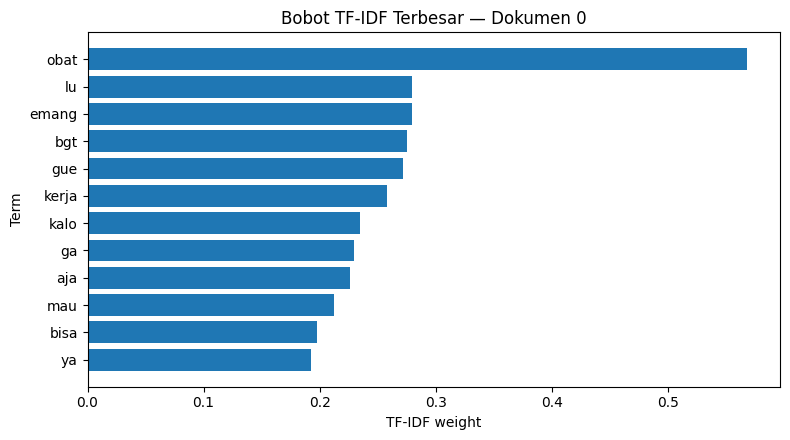

In [18]:
top_terms_doc = df_nonnol.head(12).sort_values('TF_IDF', ascending=True)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_terms_doc['Term'], top_terms_doc['TF_IDF'])
ax.set_title(f'Bobot TF-IDF Terbesar — Dokumen {idx_teks}')
ax.set_xlabel('TF-IDF weight')
ax.set_ylabel('Term')
plt.tight_layout()
plt.show()

### E8. Bandingkan beberapa dokumen dengan heatmap

Pilih 5 dokumen pertama yang memiliki sedikitnya satu term aktif. Ambil 15 term dengan **total bobot terbesar pada 5 dokumen ini**. Oleh karena itu term yang muncul bisa berbeda ketika dokumen pilihan diubah.

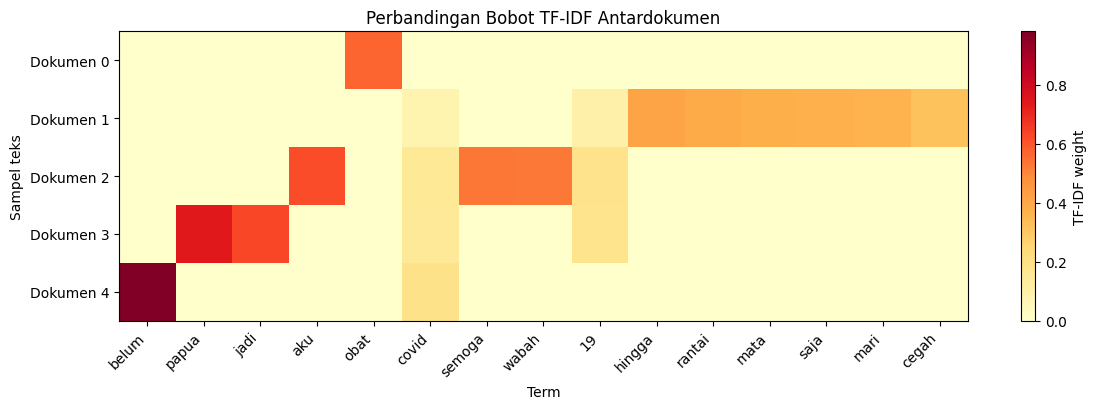

,belum,papua,jadi,aku,obat,covid,semoga,wabah,19,hingga,rantai,mata,saja,mari,cegah
Dokumen 0,0.000,0.000,0.00,0.000,0.568,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Dokumen 1,0.000,0.000,0.00,0.000,0.000,0.078,0.000,0.000,0.097,0.407,0.389,0.379,0.374,0.362,0.318
Dokumen 2,0.000,0.000,0.00,0.615,0.000,0.147,0.533,0.531,0.183,0.000,0.000,0.000,0.000,0.000,0.000
Dokumen 3,0.000,0.743,0.63,0.000,0.000,0.142,0.000,0.000,0.177,0.000,0.000,0.000,0.000,0.000,0.000
Dokumen 4,0.982,0.000,0.00,0.000,0.000,0.191,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [19]:
selected_docs = [i for i in range(Xt.shape[0]) if Xt[i].nnz > 0][:5]
df_compare = pd.DataFrame(
    Xt[selected_docs].toarray(), columns=terms,
    index=[f'Dokumen {i}' for i in selected_docs]
)
top_cols = df_compare.sum(axis=0).nlargest(15).index
df_heat = df_compare[top_cols]

fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(df_heat.to_numpy(), aspect='auto', interpolation='nearest',
               cmap='YlOrRd')
ax.set_xticks(range(len(top_cols)), top_cols, rotation=45, ha='right')
ax.set_yticks(range(len(df_heat)), df_heat.index)
ax.set_title('Perbandingan Bobot TF-IDF Antardokumen')
ax.set_xlabel('Term')
ax.set_ylabel('Sampel teks')
fig.colorbar(im, ax=ax, label='TF-IDF weight')
plt.tight_layout()
plt.show()

display(df_heat.round(3))

### E9. Eksperimen: pengaruh `max_features`

Jumlah dokumen tetap, sedangkan batas **jumlah kolom** berubah. Dalam dataset asli, jumlah term berbeda bergantung kosakata dan aturan tokenisasi. Hasil 100 vs 300 tidak boleh dibandingkan sebagai hasil akurasi model, karena belum ada model yang dilatih.

In [20]:
hasil_dimensi = []
for batas in [50, 100, 300]:
    v = TfidfVectorizer(max_features=batas)
    Xv = v.fit_transform(documents)
    hasil_dimensi.append({
        'max_features': batas,
        'jumlah_dokumen': Xv.shape[0],
        'jumlah_fitur_aktual': Xv.shape[1],
        'nonzero_entries': Xv.nnz
    })
display(pd.DataFrame(hasil_dimensi))

,max_features,jumlah_dokumen,jumlah_fitur_aktual,nonzero_entries
0,50,905,50,4744
1,100,905,100,6074
2,300,905,300,8653


### E10. Batasan representasi teks

TF-IDF menjawab **seberapa term muncul dan bagaimana bobotnya di dokumen**, bukan memahami maksud kalimat seperti manusia. Angka `max_features` membatasi kosakata; term di luar kosakata tidak mendapat koordinat. Dua kalimat dengan himpunan kata sama tetapi urutan berbeda dapat memiliki vektor yang sama pada konfigurasi dasar unigram. Praktikum 09 mempelajari penggunaan TF-IDF dalam *pipeline klasifikasi teks* dan cara evaluasinya.

## F. Representasi citra: gambar → tensor RGB → vektor

Citra digital dibentuk oleh piksel. Pada citra RGB:

- Dimensi ke-1 = **tinggi (H)**, jumlah baris piksel.
- Dimensi ke-2 = **lebar (W)**, jumlah kolom piksel.
- Dimensi ke-3 = **kanal warna** (**R**, **G**, **B**).

Representasi array `(H, W, 3)` disebut tensor berorde tiga. Setiap koordinat `(baris, kolom)` memiliki tiga nilai warna dalam rentang **0–255** untuk gambar 8-bit RGB.

**Penting:** *flatten* mengubah susunan koordinat menjadi vektor 1D tanpa membuang nilainya, tetapi **tidak lagi menampilkan struktur spasial secara eksplisit**. Berbeda dengan *resize*, yang dapat menghilangkan detail gambar.

### F1. Buka dan tampilkan citra asli

Perhatikan perbedaan `Image` (objek PIL yang bisa ditampilkan via `display`) dengan array NumPy (`original`). `img.imshow()` **bukan** metode untuk objek `PIL.Image`.

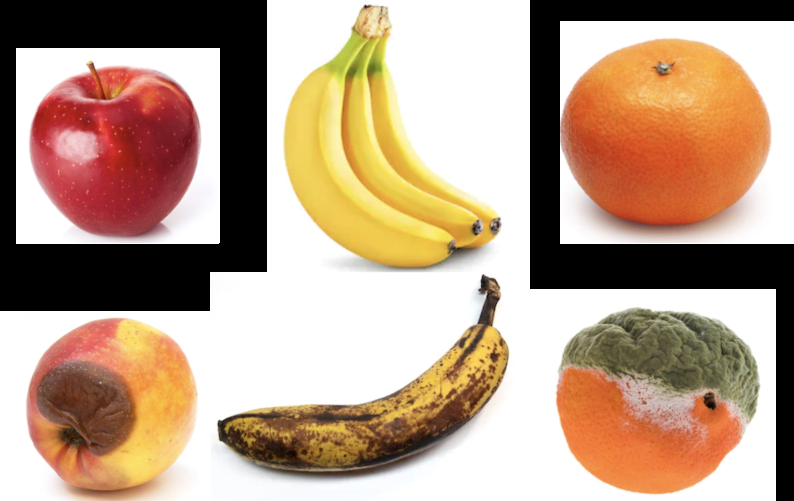

Ukuran PIL (lebar, tinggi): (794, 501)
Shape array (H, W, C)   : (501, 794, 3)
Tipe data               : uint8
Nilai piksel minimum/maksimum: 0 255


In [21]:
img = Image.open(DATA_DIR / 'fruits.png').convert('RGB')
original = np.asarray(img)

display(img)
print('Ukuran PIL (lebar, tinggi):', img.size)
print('Shape array (H, W, C)   :', original.shape)
print('Tipe data               :', original.dtype)
print('Nilai piksel minimum/maksimum:', original.min(), original.max())

### F2. Satu piksel sebagai tiga fitur kanal warna

`original[row, col]` mengambil vektor tiga kanal pada lokasi tersebut. Indeks dimulai dari `0`, sehingga `original[0, 0]` adalah piksel **pojok kiri atas**.

In [22]:
baris, kolom = 0, 0
pixel_rgb = original[baris, kolom]
print('Koordinat piksel (baris, kolom):', (baris, kolom))
print('Nilai [R, G, B]:', pixel_rgb.tolist())
display(pd.DataFrame({
    'Kanal': ['Red', 'Green', 'Blue'],
    'Nilai': pixel_rgb.astype(int)
}))

Koordinat piksel (baris, kolom): (0, 0)
Nilai [R, G, B]: [0, 0, 0]


,Kanal,Nilai
0,Red,0
1,Green,0
2,Blue,0


### F3. Visualisasi kanal R, G, B

Setiap kanal memiliki matriks berukuran `(H, W)`. Pada visualisasi grayscale di bawah, intensitas yang lebih terang menunjukkan nilai kanal lebih besar; **ketiganya tidak identik**.

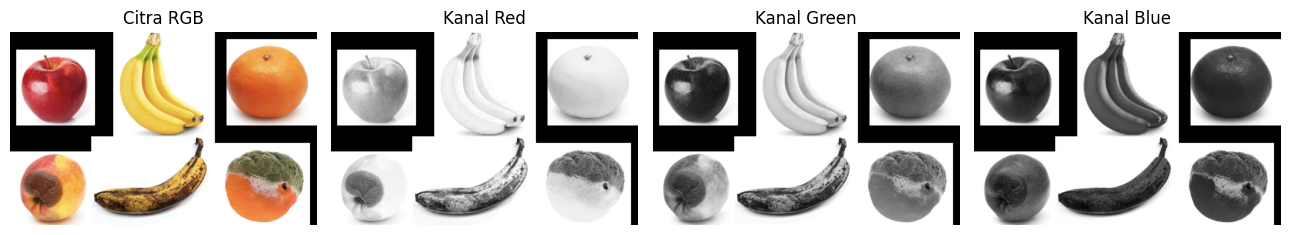

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
axes[0].imshow(original)
axes[0].set_title('Citra RGB')
for j, kanal in enumerate(['Red', 'Green', 'Blue']):
    axes[j + 1].imshow(original[:, :, j], cmap='gray', vmin=0, vmax=255)
    axes[j + 1].set_title(f'Kanal {kanal}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### F4. Resize sebagai demonstrasi pengurangan dimensi

Citra asli cukup besar sehingga tidak nyaman ditampilkan sebagai daftar nilai piksel. Untuk mengamati struktur, lakukan **resize** ke `16 × 16` dan bandingkan bentuknya. Resampling menghasilkan piksel baru; *resize* bukan sekadar memilih koordinat dari array asli.

Tensor asli (H,W,C): (501, 794, 3)
Tensor 16x16      : (16, 16, 3)
Jumlah nilai RGB asli: 1193382
Jumlah nilai RGB 16x16: 768


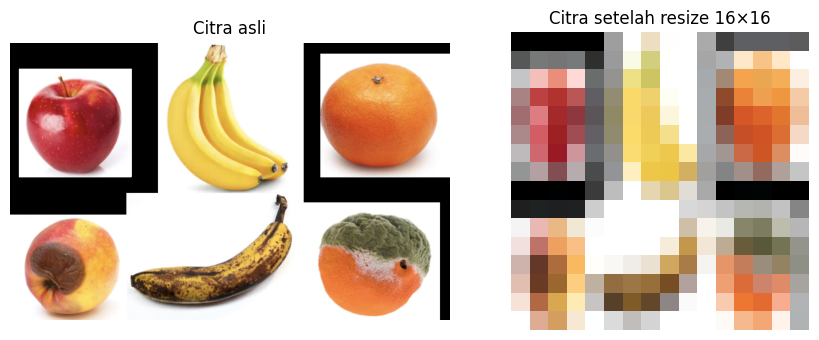

In [24]:
img_16 = img.resize((16, 16))
small = np.asarray(img_16)

print('Tensor asli (H,W,C):', original.shape)
print('Tensor 16x16      :', small.shape)
print('Jumlah nilai RGB asli:', original.size)
print('Jumlah nilai RGB 16x16:', small.size)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].imshow(original)
axes[0].set_title('Citra asli')
axes[1].imshow(small, interpolation='nearest')
axes[1].set_title('Citra setelah resize 16×16')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### F5. Membentuk vektor fitur dari tensor (*flatten*)

`reshape(-1)` meratakan semua nilai RGB menurut urutan memori array NumPy (default C-order): R, G, B untuk tiap piksel, dilanjutkan ke piksel berikutnya per baris. Vektor 16×16 RGB memiliki `16 × 16 × 3 = 768` elemen.

*Flatten* mempertahankan **jumlah nilai**, tidak mempertahankan label baris/kolom secara eksplisit. Karena itu arsitektur seperti CNN sering mempertahankan struktur H×W×C.

In [25]:
vektor_kecil = small.reshape(-1)
vektor_asli = original.reshape(-1)

print('Shape tensor 16×16:', small.shape)
print('Shape vektor kecil:', vektor_kecil.shape)
print('Shape vektor asli:', vektor_asli.shape)
print('12 nilai pertama pada vektor 16×16:')
display(pd.DataFrame({
    'Feature_Index': np.arange(12),
    'Pixel_Value': vektor_kecil[:12]
}))
assert vektor_kecil.size == 16 * 16 * 3

Shape tensor 16×16: (16, 16, 3)
Shape vektor kecil: (768,)
Shape vektor asli: (1193382,)
12 nilai pertama pada vektor 16×16:


,Feature_Index,Pixel_Value
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
5,5,0
6,6,0
7,7,0
8,8,0
9,9,0


### F6. Menghubungkan koordinat piksel dan posisi dalam vektor

Untuk citra RGB yang di-*flatten* berurutan per baris, posisi dasar piksel `(row, col)` adalah `(row × width + col) × 3`. Tiga elemen berikutnya adalah `[R, G, B]`.

In [26]:
row, col = 2, 3
awal = (row * small.shape[1] + col) * 3
print('RGB pada tensor:', small[row, col].tolist())
print('RGB pada vektor:', vektor_kecil[awal:awal + 3].tolist())
print('Indeks fitur pada vektor:', list(range(awal, awal + 3)))
assert np.array_equal(small[row, col], vektor_kecil[awal:awal + 3])

RGB pada tensor: [255, 217, 213]
RGB pada vektor: [255, 217, 213]
Indeks fitur pada vektor: [105, 106, 107]


### F7. Melihat data piksel bagian kecil sebagai tabel

Matriks di bawah menampilkan **nilai kanal Red** pada area 5×5 piksel pertama dari citra berukuran 16×16. Untuk melihat kanal Green/Blue, ubah indeks kanal dari `0` menjadi `1` atau `2`.

In [27]:
red_patch = small[:5, :5, 0]
display(pd.DataFrame(
    red_patch,
    index=[f'Row {i}' for i in range(5)],
    columns=[f'Col {j}' for j in range(5)]
))

,Col 0,Col 1,Col 2,Col 3,Col 4
Row 0,0,0,0,0,0
Row 1,86,119,118,119,47
Row 2,196,244,235,255,106
Row 3,167,189,177,187,96
Row 4,160,222,163,142,91


## G. Membandingkan ruang fitur tiga modalitas

| Jenis data | Input space | Bentuk fitur contoh | Makna satu koordinat |
|---|---|---|---|
| Tabular | `Country`, `Age`, `Salary` | Matriks `(10, 5)` | Atribut numerik atau indikator kategori |
| Teks | Dokumen/kalimat | Matriks sparse `(905, ≤300)` | Bobot term yang terpilih |
| Citra | Pixel RGB | Tensor `(H, W, 3)` atau vektor `(H×W×3,)` | Intensitas kanal pada lokasi piksel |

Ukuran pada tabel adalah **contoh dari dataset paket**, bukan aturan umum untuk semua dataset.

Jangan mencampur konsep jumlah fitur dengan jumlah sampel: **mengubah dimensi representasi tidak otomatis menambah atau mengurangi sampel**. Demikian pula, bobot TF-IDF tidak sebanding satuannya dengan gaji atau intensitas RGB.

In [28]:
ringkasan = pd.DataFrame([
    {'Modalitas':'Tabular', 'Sampel':X_tabular.shape[0],
     'Fitur/elemen per sampel':X_tabular.shape[1],
     'Struktur':'Matriks numerik + NaN'},
    {'Modalitas':'Teks (TF-IDF)', 'Sampel':Xt.shape[0],
     'Fitur/elemen per sampel':Xt.shape[1],
     'Struktur':'Sparse matrix'},
    {'Modalitas':'Citra RGB asli', 'Sampel':1,
     'Fitur/elemen per sampel':original.size,
     'Struktur':f'Tensor {original.shape} / vektor'},
    {'Modalitas':'Citra 16×16 RGB', 'Sampel':1,
     'Fitur/elemen per sampel':vektor_kecil.size,
     'Struktur':f'Tensor {small.shape} / vektor'},
])
display(ringkasan)

,Modalitas,Sampel,Fitur/elemen per sampel,Struktur
0,Tabular,10,5,Matriks numerik + NaN
1,Teks (TF-IDF),905,300,Sparse matrix
2,Citra RGB asli,1,1193382,"Tensor (501, 794, 3) / vektor"
3,Citra 16×16 RGB,1,768,"Tensor (16, 16, 3) / vektor"


### G1. Pemeriksaan hasil (checkpoint)

Sel berikut membantu mendeteksi jika sel terdahulu belum dijalankan atau kolom berubah tanpa sengaja.

In [29]:
assert len(X_raw) == len(X_tabular) == len(y)
assert set(encoded_names).issubset(X_tabular.columns)
assert len(documents) == Xt.shape[0]
assert Xt.shape[1] == len(terms)
assert original.shape[2] == 3
assert small.shape == (16, 16, 3)
assert np.array_equal(small.reshape(-1).reshape(small.shape), small)
print('Checkpoint selesai: bentuk matriks, kolom, dan piksel konsisten.')

Checkpoint selesai: bentuk matriks, kolom, dan piksel konsisten.


## H. Latihan pemahaman (jawab sebelum membuka solusi)

**L1.** Jelaskan pengertian sampel, fitur, target, input space, dan feature space dalam satu contoh sederhana.  
**L2.** Jelaskan arti `X.shape == (10, 5)` dan `X[0].shape == (5,)`.  
**L3.** Mengapa `Country` tidak boleh langsung dianggap memiliki urutan `France=0, Germany=1, Spain=2` untuk menghitung jarak?  
**L4.** Mengapa `Purchased` tidak termasuk dalam `X_tabular`?  
**L5.** Apa perbedaan vektor count dan TF-IDF? Apakah nilai TF-IDF probabilitas?  
**L6.** Mengapa sebagian besar nilai pada TF-IDF bernilai nol?  
**L7.** Apa arti dimensi `(H, W, 3)` pada sebuah citra RGB?  
**L8.** Jika citra 20×10 RGB di-*flatten*, berapa panjang vektornya?  
**L9.** Bedakan **resize** dengan **flatten** terkait ukuran dan informasi.  
**L10.** Mengapa kita tidak mengimputasi missing value atau menormalisasi `Salary` dalam Praktikum 02?  

Tuliskan jawaban sendiri terlebih dahulu. Kunci jawaban konseptual tersedia di bagian **J**.

## I. Latihan kode dan tugas terapan

### I1. Delapan latihan kode

**P1.** Tampilkan `shape` dan semua nama fitur pada `X_tabular`; sebutkan kolom yang berasal dari One-Hot Encoding.  
**P2.** Tampilkan **record ke-4** (indeks `3`), bandingkan data asal, vektor fitur, dan target.  
**P3.** Hitung jumlah nilai `1` dalam semua kolom One-Hot untuk setiap baris; interpretasikan hasilnya.  
**P4.** Ubah kategori menjadi `Spain` dan `Italy`, lalu tampilkan hasil `enc.transform` tanpa melakukan `fit` ulang.  
**P5.** Pilih dokumen berindeks `10`. Tampilkan teks asal dan lima term dengan bobot TF-IDF tertinggi. Bila semua nol, jelaskan penyebab yang mungkin.  
**P6.** Bandingkan jumlah kolom fitur TF-IDF ketika `max_features=100` dan `max_features=300`.  
**P7.** Dari citra asli, ambil piksel `(10, 20)` dan tampilkan nilai R, G, B.  
**P8.** Resize citra menjadi `8×8`, lakukan flatten, hitung jumlah elemen dan verifikasi hasilnya.

### I2. Tiga tantangan terapan

**T1 — Tabular:** Tunjukkan pengaruh penghilangan kolom `Country` terhadap dimensi matriks fitur (tanpa menghapus target).  
**T2 — Teks:** Tampilkan jumlah fitur aktif (`nnz`) pada sepuluh dokumen pertama; jelaskan mengapa bervariasi.  
**T3 — Citra:** Bandingkan jumlah elemen pada tensor RGB untuk ukuran `8×8`, `16×16`, dan `32×32`; jelaskan dampaknya terhadap kebutuhan penyimpanan representasi mentah.

**Output mahasiswa:** tabel/dimensi dan interpretasi singkat untuk setiap latihan. **Semua solusi dapat dieksekusi** pada bagian J; kerjakan dahulu secara mandiri.

## J. Kunci jawaban dan pembahasan

> Bagian ini sengaja diletakkan **setelah seluruh praktik** agar mahasiswa dapat mencoba sendiri terlebih dahulu. Jawaban kode menggunakan variabel yang sudah dibuat pada bagian sebelumnya.

### J1. Jawaban konsep L1–L5

- **L1:** Sampel = satu observasi, fitur = atribut input, target = keluaran yang ingin diprediksi; *input space* memuat informasi asal (misalnya negara, usia), dan *feature space* memuat koordinat representasinya (usia + indikator negara).
- **L2:** `(10,5)` = 10 baris observasi dan 5 fitur; `(5,)` = vektor satu sampel dengan 5 elemen.
- **L3:** Nama negara adalah kategori nominal tanpa urutan/jarak numerik alami; kode 0, 1, 2 berisiko menyiratkan urutan dan jarak buatan.
- **L4:** `Purchased` adalah target `y`, sehingga tidak boleh masuk fitur prediksi `X`.
- **L5:** Count menyimpan frekuensi term mentah; TF-IDF memberi bobot frekuensi term dengan komponen kelangkaan antardokumen. Bobot TF-IDF **bukan probabilitas**.

### J2. Jawaban konsep L6–L10

- **L6:** Satu dokumen hanya mengandung sebagian kecil kosakata korpus, sehingga koordinat term lainnya nol. Pembatasan `max_features` juga membuat term tertentu tidak tersedia.
- **L7:** `H` = jumlah baris piksel, `W` = jumlah kolom piksel, `3` = tiga kanal RGB.
- **L8:** `20 × 10 × 3 = 600` elemen.
- **L9:** *Resize* mengubah resolusi spasial dan dapat kehilangan detail; *flatten* hanya mengubah bentuk tensor menjadi vektor tanpa mengurangi jumlah nilai.
- **L10:** Fokus modul ini **membangun dan memahami representasi fitur**. Imputasi, scaling, dan protokol fit pada data train dibahas di Praktikum 03 agar kedua praktikum tidak menduplikasi kompetensi inti.

### J3. Solusi latihan kode P1–P2

P1 menguji arti `shape` dan koordinat hasil encoder; P2 melihat vektor dari **satu observasi tertentu**.

In [30]:
# Solusi P1
print('Shape:', X_tabular.shape)
print('Semua fitur:', X_tabular.columns.tolist())
print('Fitur hasil One-Hot:', list(encoded_names))

# Solusi P2 — record ke-4 = indeks 3
idx = 3
print('\nData asal:')
display(data.iloc[[idx]])
print('Fitur representasi:')
display(X_tabular.iloc[[idx]])
print('Target:', y.iloc[idx])

Shape: (10, 5)
Semua fitur: ['Age', 'Salary', 'Country_France', 'Country_Germany', 'Country_Spain']
Fitur hasil One-Hot: ['Country_France', 'Country_Germany', 'Country_Spain']

Data asal:


,Country,Age,Salary,Purchased
3,Spain,38.0,61000.0,No


Fitur representasi:


,Age,Salary,Country_France,Country_Germany,Country_Spain
3,38.0,61000.0,0,0,1


Target: No


### J4. Solusi P3–P4 — indikator kategori

Karena semua sampel memiliki negara yang valid dalam kosakata `enc`, jumlah indikator aktif semestinya `1` per baris. Kategori baru yang tidak dikenal dipetakan ke seluruh nol.

In [31]:
# Solusi P3
jumlah_aktif = df_country.sum(axis=1)
display(jumlah_aktif.rename('Jumlah indikator aktif').to_frame())
print('Semua record memiliki satu kategori aktif:', bool((jumlah_aktif == 1).all()))

# Solusi P4
tes_country = pd.DataFrame({'Country': ['Spain', 'Italy']})
hasil_country = pd.DataFrame(enc.transform(tes_country), columns=encoded_names).astype(int)
display(pd.concat([tes_country, hasil_country], axis=1))

,Jumlah indikator aktif
0,1
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1


Semua record memiliki satu kategori aktif: True


,Country,Country_France,Country_Germany,Country_Spain
0,Spain,0,0,1
1,Italy,0,0,0


### J5. Solusi P5–P6 — fitur dokumen

Tampilkan seluruh koordinat nonnol untuk dokumen ke-11 (indeks `10`), lalu ambil bobot terbesar. **Jika vektor semua nol**, bukan berarti tweet kosong: seluruh termnya bisa saja berada di luar kosakata terpilih atau terbuang oleh aturan tokenisasi.

In [32]:
# Solusi P5
idx = 10
print('Tweet:', documents.iloc[idx])
fitur_10 = pd.DataFrame({
    'Term': terms, 'TF_IDF': Xt[idx].toarray().ravel()
})
fitur_10 = (fitur_10[fitur_10.TF_IDF > 0]
            .sort_values('TF_IDF', ascending=False))
print('Term nonnol:', len(fitur_10))
display(fitur_10.head(5).round(4))

# Solusi P6
for n in (100, 300):
    tmp = TfidfVectorizer(max_features=n).fit_transform(documents)
    print(f'max_features={n}: shape={tmp.shape}')

Tweet: Ya Allah kami memohon pada mu perkenankanlah doa doa kami kerana sesungguhnya engkaulah yang maha pengasih lagi maha penyayang...Ya Allah lindungilah kami dari penyakit berjangkit covid 19... Aamiin.. aamiin ya rabbal a'lamin..stay at home.. jangan keluar rumah
Term nonnol: 16


,Term,TF_IDF
118,kami,0.4895
76,doa,0.3914
295,ya,0.3909
8,aamiin,0.3785
16,allah,0.3158


max_features=100: shape=(905, 100)
max_features=300: shape=(905, 300)


### J6. Solusi P7–P8 — piksel dan vektor

Ukuran `8×8` RGB menghasilkan `8×8×3=192` elemen, terlepas dari isi piksel.

In [33]:
# Solusi P7
print('Piksel (row=10, col=20):', original[10, 20].tolist())

# Solusi P8
img_8 = np.asarray(img.resize((8, 8)))
flat_8 = img_8.reshape(-1)
print('Tensor 8×8:', img_8.shape)
print('Vektor    :', flat_8.shape)
assert len(flat_8) == 8 * 8 * 3

Piksel (row=10, col=20): [0, 0, 0]
Tensor 8×8: (8, 8, 3)
Vektor    : (192,)


### J7. Solusi tantangan T1–T3

**T1:** menghapus satu atribut kategori asli tetapi **tetap menyimpan** numerik berarti dimensi menjadi dua, bukan lima.  
**T2:** `nnz` bervariasi karena jumlah dan jenis term yang termasuk kosakata berbeda antardokumen.  
**T3:** jumlah elemen RGB mentah bertumbuh mengikuti luas gambar (`H × W × 3`), sehingga resolusi lebih besar memerlukan lebih banyak elemen.

In [34]:
# Solusi T1
hanya_numerik = X_tabular[numerical_cols].copy()
print('Tabular semua fitur:', X_tabular.shape)
print('Tanpa Country:', hanya_numerik.shape)

# Solusi T2
nnz_pertama = pd.DataFrame({
    'Dokumen': np.arange(10),
    'Jumlah term aktif': [Xt[i].nnz for i in range(10)]
})
display(nnz_pertama)

# Solusi T3
ukuran_citra = pd.DataFrame([
    {'Resolusi': f'{s}×{s}', 'Jumlah_elemen_RGB': s * s * 3}
    for s in [8, 16, 32]
])
display(ukuran_citra)

Tabular semua fitur: (10, 5)
Tanpa Country: (10, 2)


,Dokumen,Jumlah term aktif
0,0,13
1,1,10
2,2,5
3,3,4
4,4,2
5,5,7
6,6,1
7,7,12
8,8,14
9,9,12


,Resolusi,Jumlah_elemen_RGB
0,8×8,192
1,16×16,768
2,32×32,3072


## K. Evaluasi mandiri dan persiapan Praktikum 03

Sebelum beralih, pastikan dapat menjawab:

- Apakah saya dapat membedakan **baris sampel**, **kolom fitur**, dan **label**?
- Apakah saya dapat menunjukkan **satu vektor tabular** hasil One-Hot untuk record tertentu?
- Apakah saya dapat menampilkan **top term TF-IDF dari satu dokumen** tanpa mengubah seluruh sparse matrix menjadi dense?
- Apakah saya dapat menjelaskan bagaimana **satu piksel RGB** serta **tensor citra** menjadi fitur numerik?
- Apakah saya dapat menjelaskan mengapa `fit_transform()` yang dilakukan pada seluruh dataset di demonstrasi ini **tidak boleh disalin langsung** untuk evaluasi model prediksi?

### Ringkasan

1. **Tabular:** fitur dapat berupa atribut numerik dan indikator dari kategori.
2. **Teks:** panjang dokumen yang bervariasi dapat direpresentasikan sebagai vektor tetap menurut kosakata.
3. **Citra:** posisi spasial dan kanal membentuk tensor; flatten mengubah bentuk menjadi vektor.
4. **Dimensi fitur** bergantung pada pilihan representasi dan tidak sama dengan jumlah sampel.
5. Membentuk representasi numerik **belum berarti** dataset sudah bebas nilai kosong, terskala dengan benar, atau valid untuk training.

**Modul selanjutnya — Praktikum 03: Data Preprocessing.** Kita akan menangani missing value pada `Data.csv`, melakukan imputation/scaling, dan membahas pembagian train-test agar evaluasi tidak mengalami *data leakage*.